# Análisis Exploratorio Logístico y Comercial

Análisis sobre el dataset limpio `pedidos_logistica_limpios.csv` (500 registros). Se evalúa la distribución de estados de entrega, diferencia entre ingreso bruto e ingreso efectivo, desempeño por región, categoría y evolución mensual.

In [17]:
%mamba install pandas
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

df = pd.read_csv("pedidos_logistica_limpios.csv")
df["fecha_pedido"] = pd.to_datetime(df["fecha_pedido"])
df["ingreso_entregado"] = df["ingreso_total"].where(df["estado_entrega"] == "Entregado", 0)
df.head()

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 0.938 seconds
All requested packages already installed.


,pedido_id,fecha_pedido,fecha_entrega,cliente,region,categoria,monto_venta,costo_envio,estado_entrega,ingreso_total,tipo_movimiento,dias_entrega,fecha_pedido_str,fecha_entrega_str,dias_entrega_limpio,ingreso_entregado
0,ORD-10000,2026-07-03,NaN,Camila Martínez,Región Metropolitana,Vestuario,-24280.0,2990.0,NaN,0,Devolución / Ajuste,NaN,03/07/2026,NaN,NaN,0
1,ORD-10001,2026-07-09,2026-07-24,Valentina Fuentes,Valparaíso,Calzado,371470.0,6990.0,Devuelto,378460,Venta,15.0,09/07/2026,24/07/2026,15.0,0
2,ORD-10002,2026-08-13,2026-08-19,Diego González,Región Metropolitana,Belleza,119180.0,6990.0,Entregado,126170,Venta,6.0,13/08/2026,19/08/2026,6.0,126170
3,ORD-10003,2026-09-02,2026-09-14,Tomás Silva,Región Metropolitana,Hogar,370400.0,6990.0,Entregado,377390,Venta,12.0,02/09/2026,14/09/2026,12.0,377390
4,ORD-10004,2026-09-08,NaN,Nicolás Fuentes,Araucanía,Hogar,192680.0,6990.0,En Tránsito,199670,Venta,NaN,08/09/2026,NaN,NaN,0


### 1. Resumen Ejecutivo: Ingreso Bruto vs. Ingreso Efectivo

No todo pedido con monto positivo se traduce en venta concretada: los pedidos `Cancelado` y `Devuelto` representan pérdida comercial directa, mientras que `En Tránsito` y `Pendiente` aún están por cerrarse.

In [18]:
ingreso_bruto = df["ingreso_total"].sum()
ingreso_efectivo = df["ingreso_entregado"].sum()
ingreso_perdido = df.loc[df["estado_entrega"].isin(["Cancelado", "Devuelto"]), "ingreso_total"].sum()

print(f"Total pedidos: {len(df)}")
print(f"Ingreso bruto (todas las ventas > 0): {ingreso_bruto:,.0f} CLP".replace(",", "."))
print(f"Ingreso efectivo (solo Entregado):   {ingreso_efectivo:,.0f} CLP".replace(",", "."))
print(f"Monto en Cancelado + Devuelto:       {ingreso_perdido:,.0f} CLP".replace(",", "."))

print("\nDistribución por tipo de movimiento:")
print(df["tipo_movimiento"].value_counts())

print("\nDistribución por estado de entrega:")
estados = df.groupby("estado_entrega", dropna=False).agg(
    pedidos=("pedido_id", "count"),
    ingreso_bruto=("ingreso_total", "sum"),
).sort_values("pedidos", ascending=False)
estados["pct_pedidos"] = (estados["pedidos"] / len(df) * 100).round(1)
print(estados)

Total pedidos: 500
Ingreso bruto (todas las ventas > 0): 109.102.840 CLP
Ingreso efectivo (solo Entregado):   69.289.110 CLP
Monto en Cancelado + Devuelto:       16.403.810 CLP

Distribución por tipo de movimiento:
tipo_movimiento
Venta                  472
Sin Monto               21
Devolución / Ajuste      7
Name: count, dtype: int64

Distribución por estado de entrega:
                pedidos  ingreso_bruto  pct_pedidos
estado_entrega                                     
Entregado           326       69289110         65.2
En Tránsito          50       11177520         10.0
Pendiente            44        8889730          8.8
Cancelado            42        9929640          8.4
Devuelto             25        6474170          5.0
NaN                  13        3342670          2.6


### 2. Desempeño por Región

Se compara volumen de pedidos, pedidos entregados, lead time promedio (`dias_entrega_limpio`), ingreso bruto e ingreso efectivo por región.

In [19]:
region_agrupada = df.groupby("region").agg(
    total_pedidos=("pedido_id", "count"),
    entregados=("estado_entrega", lambda s: (s == "Entregado").sum()),
    promedio_entrega=("dias_entrega_limpio", "mean"),
    ingreso_bruto=("ingreso_total", "sum"),
    ingreso_efectivo=("ingreso_entregado", "sum"),
).sort_values("ingreso_efectivo", ascending=False)

region_agrupada["promedio_entrega"] = region_agrupada["promedio_entrega"].round(2)
print(region_agrupada)

                      total_pedidos  entregados  promedio_entrega  ingreso_bruto  ingreso_efectivo
region                                                                                            
Región Metropolitana            240         156              6.56       50743050          31872130
Valparaíso                       70          47              6.69       14972700          10599340
Biobío                           63          47              6.96       14528530          10517360
Araucanía                        35          21              6.05        8449000           4523640
Maule                            27          18              6.24        5660320           4061920
Coquimbo                         23          17              8.00        5014270           3378970
Los Lagos                        26          11              7.08        6384760           2924250
O'Higgins                        16           9              6.50        3350210           1411500


### 3. Desempeño por Categoría

In [20]:
categoria_agrupada = df.groupby("categoria", dropna=False).agg(
    total_pedidos=("pedido_id", "count"),
    entregados=("estado_entrega", lambda s: (s == "Entregado").sum()),
    promedio_entrega=("dias_entrega_limpio", "mean"),
    ingreso_bruto=("ingreso_total", "sum"),
    ingreso_efectivo=("ingreso_entregado", "sum"),
).sort_values("ingreso_efectivo", ascending=False)

categoria_agrupada["promedio_entrega"] = categoria_agrupada["promedio_entrega"].round(2)
print(categoria_agrupada)

             total_pedidos  entregados  promedio_entrega  ingreso_bruto  ingreso_efectivo
categoria                                                                                
Belleza                 99          71              6.72       21453480          15075340
Deportes                76          49              6.80       18016740          12458110
Calzado                 88          57              5.67       17525880          10664700
Hogar                   84          49              7.25       18388640          10294310
Vestuario               69          44              7.26       15819810           9787320
Electrónica             73          47              6.62       15979800           9654890
NaN                     11           9              6.12        1918490           1354440


### 4. Evolución Mensual (Junio – Septiembre 2026)

In [21]:
df["mes"] = df["fecha_pedido"].dt.to_period("M").astype(str)
mensual = df.groupby("mes").agg(
    total_pedidos=("pedido_id", "count"),
    entregados=("estado_entrega", lambda s: (s == "Entregado").sum()),
    ingreso_bruto=("ingreso_total", "sum"),
    ingreso_efectivo=("ingreso_entregado", "sum"),
)
print(mensual)

         total_pedidos  entregados  ingreso_bruto  ingreso_efectivo
mes                                                                
2026-06            130          90       28924100          20136910
2026-07            125          78       26290800          15877140
2026-08            127          85       25987190          16347260
2026-09            118          73       27900750          16927800


### 5. Visualización de Resultados (`matplotlib`)

> Ejecutar las siguientes celdas en Jupyter / JupyterLite para renderizar los gráficos.

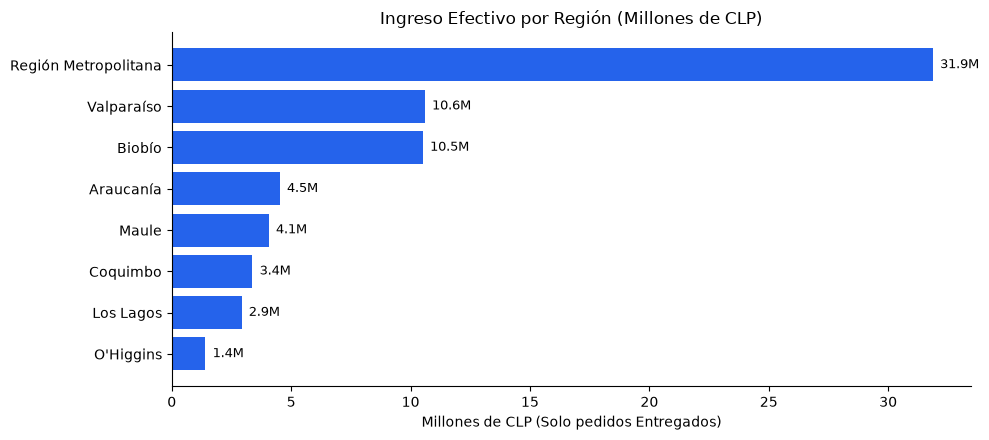

In [22]:
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

# Gráfico 1: Ingreso efectivo (CLP) por región
reg_plot = region_agrupada.sort_values("ingreso_efectivo", ascending=True)
fig, ax = plt.subplots()
ax.barh(reg_plot.index, reg_plot["ingreso_efectivo"] / 1e6, color="#2563eb")
ax.set_title("Ingreso Efectivo por Región (Millones de CLP)")
ax.set_xlabel("Millones de CLP (Solo pedidos Entregados)")
for i, v in enumerate(reg_plot["ingreso_efectivo"] / 1e6):
    ax.text(v + 0.3, i, f"{v:.1f}M", va="center", fontsize=9)
plt.tight_layout()
plt.show()

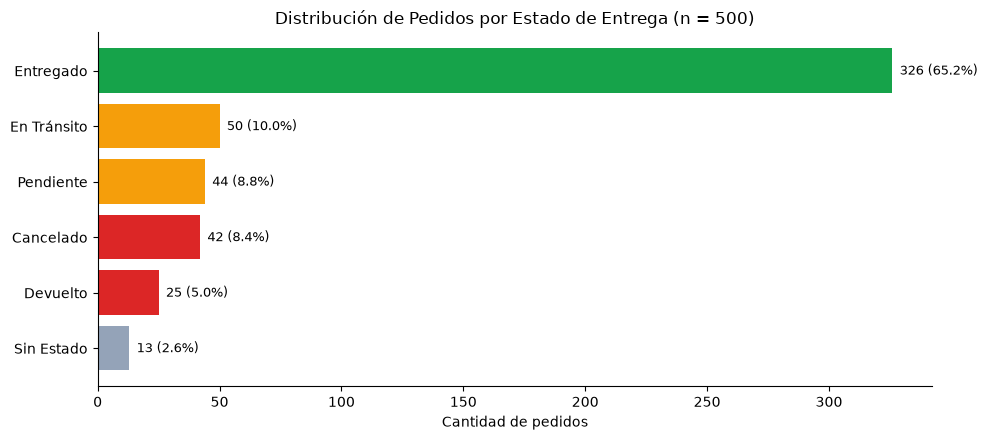

In [23]:
# Gráfico 2: Distribución de pedidos por estado de entrega
est_plot = df["estado_entrega"].fillna("Sin Estado").value_counts().sort_values(ascending=True)
colores = ["#94a3b8" if k == "Sin Estado" else "#dc2626" if k in ["Cancelado", "Devuelto"] else "#f59e0b" if k in ["En Tránsito", "Pendiente"] else "#16a34a" for k in est_plot.index]

fig, ax = plt.subplots()
ax.barh(est_plot.index, est_plot.values, color=colores)
ax.set_title("Distribución de Pedidos por Estado de Entrega (n = 500)")
ax.set_xlabel("Cantidad de pedidos")
for i, v in enumerate(est_plot.values):
    ax.text(v + 3, i, f"{v} ({v/len(df)*100:.1f}%)", va="center", fontsize=9)
plt.tight_layout()
plt.show()

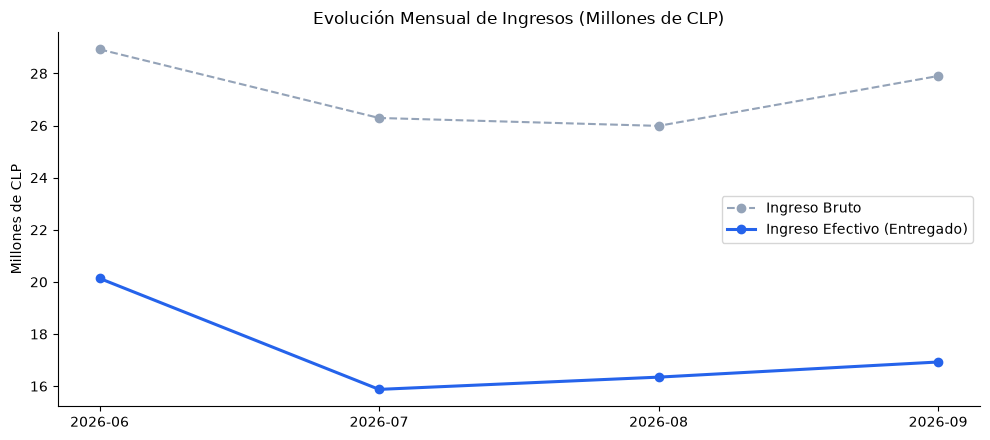

In [24]:
# Gráfico 3: Evolución mensual de ingreso bruto vs. ingreso efectivo
fig, ax = plt.subplots()
x = range(len(mensual))
ax.plot(x, mensual["ingreso_bruto"] / 1e6, marker="o", label="Ingreso Bruto", color="#94a3b8", linestyle="--")
ax.plot(x, mensual["ingreso_efectivo"] / 1e6, marker="o", label="Ingreso Efectivo (Entregado)", color="#2563eb", linewidth=2.2)
ax.set_xticks(list(x))
ax.set_xticklabels(mensual.index)
ax.set_title("Evolución Mensual de Ingresos (Millones de CLP)")
ax.set_ylabel("Millones de CLP")
ax.legend()
plt.tight_layout()
plt.show()

### Conclusiones del Análisis Logístico y Comercial

* **Brecha entre ingreso bruto y efectivo:** aunque los 472 pedidos clasificados como `Venta` suman un ingreso bruto de **109.102.840 CLP**, solo **326 pedidos (65,2%)** figuran como `Entregado`, generando un **ingreso efectivo de 69.289.110 CLP**. Los **67 pedidos** en estado `Cancelado` (42) o `Devuelto` (25) representan una fuga de **16.403.810 CLP** (13,4% de los pedidos).
* **Desempeño por región:** la **Región Metropolitana** concentra el mayor volumen y facturación efectiva (**240 pedidos** y **31.872.130 CLP**), seguida por **Valparaíso** (**10.599.340 CLP** en 70 pedidos) y **Biobío** (**10.517.360 CLP** en 63 pedidos). En tiempos de entrega válidos (`dias_entrega_limpio`), los promedios regionales se mantienen acotados entre **6,05 días** (**Araucanía**) y **8,00 días** (**Coquimbo**).
* **Desempeño por categoría:** **Belleza** lidera en volumen (**99 pedidos**) e ingreso efectivo (**15.075.340 CLP**), seguida por **Deportes** (**12.458.110 CLP** en 76 pedidos) y **Calzado** (**10.664.700 CLP** en 88 pedidos). El tiempo promedio de entrega por categoría oscila entre **5,67 días** (**Calzado**) y **7,26 días** (**Vestuario**).
* **Evolución temporal:** junio registró el mayor ingreso efectivo del periodo (**20.136.910 CLP**), con una baja en julio (**15.877.140 CLP**) y recuperación progresiva en agosto (**16.347.260 CLP**) y septiembre (**16.927.800 CLP**).